In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, 
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

In [3]:
rng = np.random.default_rng(42)
df= pd.DataFrame({"recency_days": np.concatenate([rng.normal(10, 4, 100),
                                    rng.normal(60, 15, 100),
                                    rng.normal(150, 30, 100)]).clip(1),
    "frequency":    np.concatenate([rng.normal(20, 4, 100),
                                    rng.normal(8, 3, 100),
                                    rng.normal(2, 1, 100)]).clip(1),
    "monetary":     np.concatenate([rng.normal(900, 150, 100),
                                    rng.normal(350, 100, 100),
                                    rng.normal(80, 40, 100)]).clip(10),
})
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

features = ["recency_days", "frequency",  "monetary"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

##### Elbow method & Silhouette score

In [5]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

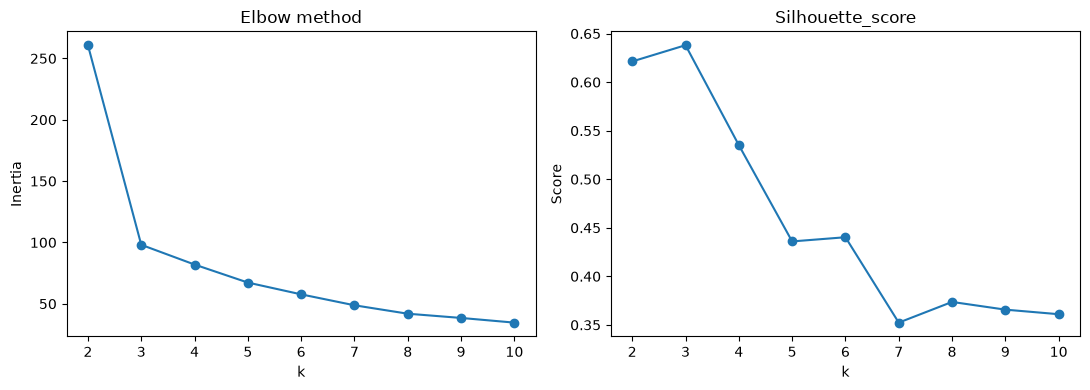

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_range, inertias, marker='o')
ax[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")

ax[1].plot(k_range, sil_scores, marker='o')
ax[1].set(title="Silhouette_score", xlabel='k', ylabel="Score")
plt.tight_layout()

In [7]:
k=3
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
df['kmeans_segment'] = kmeans.fit_predict(X_scaled)

##### Evaluation metrics

In [8]:
labels = df['kmeans_segment']
print("Silhouette score: ", silhouette_score(X_scaled, labels))
print("Davies-Bouldin :", davies_bouldin_score(X_scaled, labels))
print("Calinski-Harabasz :", calinski_harabasz_score(X_scaled, labels))

Silhouette score:  0.6380433867120956
Davies-Bouldin : 0.48902751502766145
Calinski-Harabasz : 1214.402460858716


##### Hierarchial clustering

Text(0, 0.5, 'Merge distance')

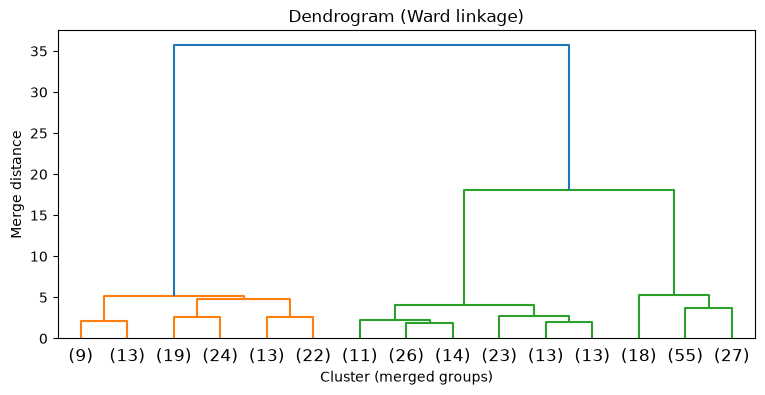

In [9]:
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(9, 4))
dendrogram(Z, truncate_mode="lastp", p=15)
plt.title("Dendrogram (Ward linkage)")
plt.xlabel("Cluster (merged groups)")
plt.ylabel("Merge distance")

In [10]:
agg = AgglomerativeClustering(n_clusters=k, linkage='ward')
df['hier_segment'] = agg.fit_predict(X_scaled)

In [11]:
ari = adjusted_rand_score(df['kmeans_segment'], df['hier_segment'])
print("Agreement between  the two clusterings (ARI): ", ari)

Agreement between  the two clusterings (ARI):  0.9799166810177865


In [13]:
profile = df.groupby('kmeans_segment')[features].mean().round(1)
profile['size'] = df['kmeans_segment'].value_counts().sort_index()
profile

,recency_days,frequency,monetary,size
kmeans_segment,,,,
0,9.8,20.5,885.3,99
1,148.9,2.0,74.4,99
2,59.5,7.8,354.3,102


Text(0.5, 1.0, 'K-Means customer segments')

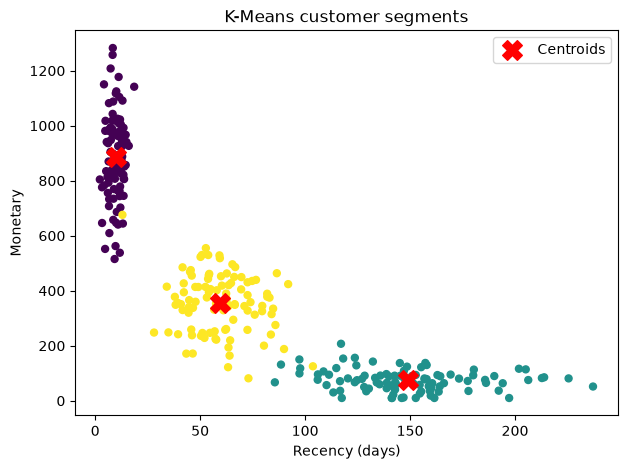

In [21]:
plt.figure(figsize=(7,5))
plt.scatter(df["recency_days"],df['monetary'], c= df['kmeans_segment'], cmap='viridis', s=25)
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 2], c='red', marker='X', s=200, label="Centroids")

plt.xlabel('Recency (days)')
plt.ylabel("Monetary")
plt.legend()
plt.title("K-Means customer segments")
